# CRNN durante 400 épocas con la partición 80/20

Se entrena desde cero hasta la época 400 para comprobar si alguna época posterior a la 66 supera el F1 macro alcanzado en la época 27 del ensayo anterior. Ambos ensayos usan las mismas señales preprocesadas, las mismas 80 personas de entrenamiento, las mismas 20 personas de evaluación, la misma arquitectura y la misma semilla.

El F1 macro se calcula y se registra después de cada época. Se conserva el primer modelo que alcanza el máximo observado. Las 20 personas participan en la selección del punto de control. El modelo anterior de la época 27 continúa disponible en su propia carpeta.

In [1]:
import hashlib
import json
import os
import sys
from datetime import datetime
from pathlib import Path
from time import perf_counter
from uuid import uuid4

os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '5')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.special import softmax
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, log_loss
from sklearn.model_selection import StratifiedKFold

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data.dvc').is_file())
sys.path.insert(0, str(ROOT/'Notebooks/auxiliares_dart_crnn'))
from crnn_contextual_mixto import bloques, entrenar_crnn, prob_crnn

DATA = ROOT/'data'
AUX = ROOT/'Notebooks/auxiliares_dart_crnn'
ficha = json.loads((DATA/'experimentos/dart_crnn_mixto/dart_666_crnn_27_20261119_191036/referencia_seleccion_80_20.json').read_text('utf8'))
contrato = ficha['contrato']
CLASES = np.array(contrato['clases'])
DESFASES = tuple(contrato['desfases'])
SEMILLA = 42
SEMILLA_PARTICION = 42
EPOCAS = 400
tf.config.experimental.enable_op_determinism()

## Personas y entradas preprocesadas

Las etiquetas e índices se leen de las tablas supervisadas. Cada espectro conserva todas las épocas de su propia noche. El entrenamiento y las métricas utilizan las épocas con etiqueta válida.

In [2]:
personas_desarrollo = set(contrato['personas_entrenamiento'])
registros_desarrollo = contrato['registros_entrenamiento']
assert len(personas_desarrollo) == 80 and len(registros_desarrollo) == 158
partes = []
for manifiesto in sorted((DATA/'processed/supervised').glob('*/manifest.json')):
    cache = json.loads(manifiesto.read_text('utf8'))
    cohorte = 'Cassette' if cache['record_ids'][0].startswith('SC') else 'Telemetry'
    if cache['preprocessing'] != contrato['preprocesamiento_dart'][cohorte]:
        continue
    meta = pd.read_parquet(manifiesto.parent/'metadata.parquet', columns=['record_id','subject_id','epoch_index'])
    meta['etapa'] = pd.read_parquet(manifiesto.parent/'labels.parquet')['stage'].to_numpy()
    partes.append(meta.assign(cohorte=cohorte))

desarrollo = pd.concat(partes, ignore_index=True)
assert desarrollo.subject_id.nunique() == 100 and desarrollo.record_id.nunique() == 197
assert not desarrollo.duplicated(['record_id','epoch_index']).any()
personas = desarrollo[['cohorte','subject_id']].drop_duplicates().sort_values(['cohorte','subject_id'])
it, iv = next(StratifiedKFold(5, shuffle=True, random_state=SEMILLA_PARTICION).split(personas, personas.cohorte))
ids_train = set(personas.iloc[it].subject_id)
ids_val = set(personas.iloc[iv].subject_id)
assert len(ids_train) == 80 and len(ids_val) == 20 and ids_train.isdisjoint(ids_val)
entreno = desarrollo[desarrollo.subject_id.isin(ids_train)]
validacion = desarrollo[desarrollo.subject_id.isin(ids_val)].sort_values(['record_id','epoch_index']).reset_index(drop=True)

assert ids_train == personas_desarrollo
assert set(entreno.record_id) == set(registros_desarrollo)
assert len(entreno) == contrato['segmentos_entrenamiento'] == 365283 and len(validacion) == 92369
assert entreno.record_id.nunique() == 158 and validacion.record_id.nunique() == 39

# Seleccionar la receta y las señales de la corrida 80/20.
receta_espectral = '61a5f1dc5fa2f1b4'
carpeta_espectral = DATA/'processed/crnn_espectral'/receta_espectral
receta = json.loads((carpeta_espectral/'preprocesamiento.json').read_text('utf8'))
assert receta['canales'] == contrato['canales_crnn'] and receta['bandas'] == contrato['bandas_hz']
entradas = {}
for rid, grupo in desarrollo.groupby('record_id', sort=False):
    cohorte = grupo.cohorte.iat[0].lower()
    archivo, = (DATA/('sleep-'+cohorte)).glob(f'{rid}*-PSG.edf')
    digest = hashlib.sha256()
    with archivo.open('rb') as f:
        for bloque in iter(lambda: f.read(4*1024*1024), b''):
            digest.update(bloque)
    huella = digest.hexdigest()
    if rid in registros_desarrollo:
        assert huella == registros_desarrollo[rid]['psg']
    ruta = carpeta_espectral/f'{archivo.stem}-{huella}.npy'
    entradas[rid] = np.load(ruta, mmap_mode='r', allow_pickle=False)
assert all(x.dtype == np.float32 and x.shape[1:] == (6,96) for x in entradas.values())
resumen = pd.concat({'Entrenamiento': entreno, 'Prueba usada para elegir la época': validacion}, names=['uso'])
display(resumen.groupby(['uso','cohorte']).agg(personas=('subject_id','nunique'), noches=('record_id','nunique'), segmentos=('etapa','size')))

# Fijar el ensayo anterior que se usa como referencia de 66 épocas.
carpeta_referencia = AUX/'resultados_crnn'/'20261119_182857_229701'
referencia = json.loads((carpeta_referencia/'resumen.json').read_text('utf8'))
curva_anterior = pd.read_csv(carpeta_referencia/'curva.csv').set_index('epoca')
assert referencia['mejor_epoca'] == 27 and referencia['epocas_completadas'] == 66
assert referencia['firma_experimento_80_20'] == ficha['firma']
assert set(referencia['personas_entrenamiento']) == ids_train
assert set(referencia['personas_prueba_usadas_para_seleccion']) == ids_val

personas  noches  segmentos
uso                               cohorte                               
Entrenamiento                     Cassette         62     122     330469
                                  Telemetry        18      36      34814
Prueba usada para elegir la época Cassette         16      31      84492
                                  Telemetry         4       8       7877

## Validación después de cada época

Se reúnen las ventanas por desfase para predecir por lotes. Cada ventana pertenece a una sola noche. Se combinan las tres predicciones de cada segmento mediante la misma media geométrica del modelo principal.

In [3]:
vistas = []
for desfase in DESFASES:
    secuencias, posiciones = [], []
    inicio = 0
    for rid, grupo in validacion.groupby('record_id', sort=False):
        noche = bloques(entradas[rid], desfase)
        secuencias.append(noche)
        posiciones.append(inicio + desfase + grupo.epoch_index.to_numpy())
        inicio += len(noche) * noche.shape[1]
    vistas.append((np.concatenate(secuencias), np.concatenate(posiciones)))
del secuencias, posiciones
y_val = pd.Categorical(validacion.etapa, categories=CLASES).codes

def probabilidades_validacion(red):
    log_p = np.zeros((len(validacion), len(CLASES)), dtype='float64')
    for secuencias, posiciones in vistas:
        p = red.predict(secuencias, batch_size=128, verbose=0).reshape(-1, len(CLASES))
        log_p += np.log(np.maximum(p[posiciones].astype('float64'), 1e-10))
    return softmax(log_p / len(vistas), axis=1)

## Entrenamiento y selección

Una sola trayectoria de entrenamiento permite comparar las épocas con los mismos pesos iniciales y el mismo orden de lotes hasta cada punto. Se guardan la curva completa y el modelo que alcanza el mejor F1 macro en validación. El tiempo de ajuste excluye la evaluación y la escritura de resultados.

La corrida no se detiene cuando el F1 baja. El seguimiento por época permite medir cuánto tiempo transcurre hasta una mejora y compararlo con el coste de completar las 400 épocas.

In [4]:
salida = AUX/'resultados_crnn_400'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
salida.mkdir(parents=True, exist_ok=False)
ruta_mejor = salida/'mejor_crnn.keras'
historial = []
mejor_f1 = -np.inf
mejor_epoca = 0
segundos_validacion = 0.
inicio_ajuste = perf_counter()

def evaluar_epoca(epoca, red):
    global mejor_f1, mejor_epoca, segundos_validacion
    inicio_val = perf_counter()
    p = probabilidades_validacion(red)
    if epoca == 1:
        rid = validacion.record_id.iat[0]
        g = validacion[validacion.record_id == rid]
        referencia = prob_crnn(red, entradas[rid], clases=CLASES, desfases=DESFASES)[g.epoch_index]
        np.testing.assert_allclose(p[g.index], referencia, rtol=1e-5, atol=1e-7)
    pred = p.argmax(axis=1)
    f1 = f1_score(y_val, pred, labels=np.arange(len(CLASES)), average='macro', zero_division=0)
    fila = dict(epoca=epoca, f1_macro=f1, exactitud=accuracy_score(y_val, pred),
                kappa=cohen_kappa_score(y_val, pred), perdida_log=log_loss(y_val, p, labels=np.arange(len(CLASES))),
                ajuste_acumulado_s=inicio_val-inicio_ajuste-segundos_validacion)
    historial.append(fila)
    if f1 > mejor_f1:
        temporal = salida/(uuid4().hex + '.keras')
        red.save(temporal)
        temporal.replace(ruta_mejor)
        mejor_f1, mejor_epoca = f1, epoca
    tmp = salida/'curva.tmp'
    pd.DataFrame(historial).to_csv(tmp, index=False)
    tmp.replace(salida/'curva.csv')
    if epoca == 66:
        diferencias = np.abs(np.asarray([f['f1_macro'] for f in historial])-curva_anterior.f1_macro.to_numpy())
        print(f'Comparación de las primeras 66 épocas con el ensayo anterior: diferencia máxima de F1 {diferencias.max():.8f}', flush=True)
    segundos_validacion += perf_counter()-inicio_val
    print(f'Época {epoca:3d}/{EPOCAS} ({epoca/EPOCAS:.0%}) | F1 macro {f1:.4f} | mejor {mejor_f1:.4f} en época {mejor_epoca}', flush=True)

print(f'Inicio de CRNN desde cero. 80 personas en entrenamiento, 20 en evaluación. Resultados en {salida.relative_to(ROOT)}', flush=True)
red = entrenar_crnn(entreno, entradas, clases=CLASES, desfases=DESFASES, semilla=SEMILLA,
                    epocas=EPOCAS, al_terminar_epoca=evaluar_epoca)

Inicio de CRNN desde cero. 80 personas en entrenamiento, 20 en evaluación. Resultados en Notebooks\auxiliares_dart_crnn\resultados_crnn_400\20261119_191036_303071


Época   1/400 (0%) | F1 macro 0.7713 | mejor 0.7713 en época 1


Época   2/400 (0%) | F1 macro 0.7779 | mejor 0.7779 en época 2


Época   3/400 (1%) | F1 macro 0.7832 | mejor 0.7832 en época 3


Época   4/400 (1%) | F1 macro 0.7790 | mejor 0.7832 en época 3


Época   5/400 (1%) | F1 macro 0.7847 | mejor 0.7847 en época 5


... (472 outputs left out)

Época 398/400 (100%) | F1 macro 0.7683 | mejor 0.7934 en época 27


Época 399/400 (100%) | F1 macro 0.7697 | mejor 0.7934 en época 27


Época 400/400 (100%) | F1 macro 0.7767 | mejor 0.7934 en época 27


CRNN · 400/400 épocas


## ¿Qué aportaron las épocas posteriores a la 66?

Se comparan el mejor punto de las primeras 66 épocas, el mejor punto posterior y la época 400. Tras recargar el modelo elegido se verifica su F1 sobre las 20 personas reservadas. El historial incluye el tiempo acumulado de ajuste por época.

,f1_macro,exactitud,kappa,perdida_log,ajuste_acumulado_s
epoca,,,,,
15,0.7826,0.9063,0.8334,0.2399,173.9398
27,0.7934,0.9127,0.8444,0.2350,298.4051
66,0.7840,0.9058,0.8324,0.2848,696.1645
74,0.7865,0.9084,0.8369,0.2794,778.2904
100,0.7796,0.9061,0.8322,0.2995,1054.5128
200,0.7774,0.9056,0.8313,0.3370,2091.3031
300,0.7696,0.9047,0.8292,0.3585,3117.8356
400,0.7767,0.9062,0.8321,0.3648,4140.7097


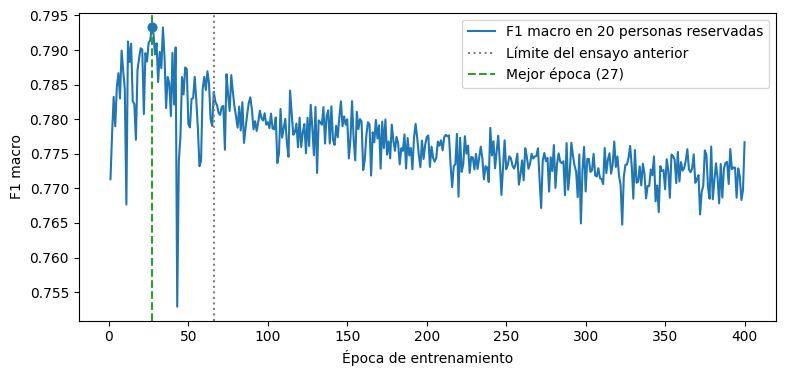

Épocas completadas: 400. Mejor época: 27. F1 macro 0.7934.
Diferencia frente a 27 épocas: +0.00 puntos porcentuales.
Notebooks\auxiliares_dart_crnn\resultados_crnn_400\20261119_191036_303071


In [5]:
if 'salida' not in globals():
    curvas = sorted((AUX/'resultados_crnn_400').glob('*/curva.csv'))
    if not curvas:
        raise FileNotFoundError('No hay una curva guardada del experimento.')
    salida = curvas[-1].parent

curva = pd.read_csv(salida/'curva.csv').set_index('epoca')
completadas = int(curva.index.max())
assert curva.index.tolist() == list(range(1, completadas + 1))
mejor_epoca = int(curva.f1_macro.idxmax())
mejor_f1 = float(curva.at[mejor_epoca,'f1_macro'])
mejor_hasta_66 = int(curva.loc[:66,'f1_macro'].idxmax())
posteriores = curva[curva.index > 66]
mejor_posterior = int(posteriores.f1_macro.idxmax()) if not posteriores.empty else None
seleccion = sorted({i for i in [15, 27, 66, 100, 200, 300, EPOCAS, mejor_hasta_66, mejor_posterior,
                                mejor_epoca, completadas] if i in curva.index})
display(curva.loc[seleccion].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curva.index, curva.f1_macro, label='F1 macro en 20 personas reservadas')
ax.scatter([27, mejor_epoca], curva.loc[[27, mejor_epoca],'f1_macro'], zorder=3)
ax.axvline(66, color='grey', linestyle=':', label='Límite del ensayo anterior')
ax.axvline(mejor_epoca, color='tab:green', linestyle='--', label=f'Mejor época ({mejor_epoca})')
ax.set(xlabel='Época de entrenamiento', ylabel='F1 macro')
ax.legend()
plt.show()

ruta_mejor = salida/'mejor_crnn.keras'
ganadora = tf.keras.models.load_model(ruta_mejor, compile=False)
probs_mejor = probabilidades_validacion(ganadora)
f1_recargado = f1_score(y_val, probs_mejor.argmax(1), labels=np.arange(len(CLASES)), average='macro')
np.testing.assert_allclose(f1_recargado, mejor_f1, rtol=0, atol=1e-10)
informe = dict(maximo_epocas=EPOCAS, epocas_completadas=completadas, mejor_epoca=mejor_epoca,
               estado='completo' if completadas == EPOCAS else 'interrumpido',
               semilla_modelo=SEMILLA, semilla_particion=SEMILLA_PARTICION, mejor_f1_macro=mejor_f1,
               f1_macro_epoca_15=float(curva.loc[15,'f1_macro']),
               ajuste_hasta_mejor_s=float(curva.loc[mejor_epoca,'ajuste_acumulado_s']),
               ajuste_total_completado_s=float(curva.iloc[-1].ajuste_acumulado_s),
               personas_entrenamiento=sorted(ids_train), personas_prueba_usadas_para_seleccion=sorted(ids_val),
               firma_experimento_80_20=ficha['firma'], receta_espectral=receta_espectral,
               sha256_modelo=hashlib.sha256(ruta_mejor.read_bytes()).hexdigest())
informe.update(epoca_mejor_hasta_66=mejor_hasta_66, epoca_mejor_posterior_a_66=mejor_posterior,
               f1_epoca_27=float(curva.loc[27,'f1_macro']),
               f1_mejor_hasta_66=float(curva.at[mejor_hasta_66,'f1_macro']),
               f1_mejor_posterior_a_66=None if mejor_posterior is None else float(curva.at[mejor_posterior,'f1_macro']),
               f1_referencia_anterior=float(referencia['mejor_f1_macro']))
(salida/'resumen.json').write_text(json.dumps(informe, ensure_ascii=False, indent=2), encoding='utf8')
print(f'Épocas completadas: {completadas}. Mejor época: {mejor_epoca}. F1 macro {mejor_f1:.4f}.')
print(f'Diferencia frente a 27 épocas: {(mejor_f1-curva.loc[27,"f1_macro"])*100:+.2f} puntos porcentuales.')
print(salida.relative_to(ROOT))